# Lab 3 — Millions of TVs, Who Is Watching?
Name: Tymofii Pohodaiev | Group: КМ-43

## Setup

In [28]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

In [29]:
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
TEN = BIG + ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]
DAYS = pd.date_range("2024-10-14", "2024-10-27").date

def broadcast_day(ts):
    return (ts - pd.Timedelta(hours=6)).dt.date

acr = acr_sessions.copy()
acr["start"] = pd.to_datetime(acr["start_utc"], utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["end"] = pd.to_datetime(acr["end_utc"], utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["bday"] = broadcast_day(acr["start"])
acr["hours"] = (acr["end"] - acr["start"]).dt.total_seconds() / 3600

edited = acr[acr["hours"] * 60 >= 1]
live = edited[edited["session_type"] == "live"]
in_tab = edited.groupby("bday")["tv_id"].nunique()
tv_days = in_tab.sum()

dw = daily_weights.copy()
dw["bday"] = pd.to_datetime(dw["broadcast_date"]).dt.date
dw = dw[dw["bday"].isin(DAYS) & (dw["weight"] > 0)]
hh = dw[dw["resp_type"] == "H"]
panel = hh.groupby("respondent_id")["weight"].mean().rename("weight").to_frame()

va = viewer_attributes[pd.to_numeric(viewer_attributes["value"], errors="coerce") != 0]
age = pd.to_numeric(va[va["attr_id"] == 300].set_index("respondent_id")["value"], errors="coerce")
income = va[va["attr_id"].between(811, 816)].merge(attributes, on="attr_id").set_index("respondent_id")["attr_name"]
region_ids = attributes.loc[attributes["attr_group"].str.contains("region", case=False), "attr_id"]
region = va[va["attr_id"].isin(region_ids)].merge(attributes, on="attr_id").set_index("respondent_id")["attr_name"]

## Task 1.1 — Five questions

**Answer:**

| Question | `acr_sessions` | Lab 1 `viewings` |
| --- | --- | --- |
| Grain | one viewing session on one TV | one viewing event of one panelist (home or person) |
| Key | `session_id`; TV by `tv_id`, home by `hashed_ip` | `viewing_id`; panelist by `respondent_id` |
| Coverage | 29,940 opted-in smart TVs of one brand; any network, app or input | about 4,000 homes and 10,000 people; ten networks only |
| Weight | none: every TV counts once | daily weights project to all US TV homes and persons |
| Provenance | TV maker's ACR feed, collected for ad sales | people-meter panel, recruited and calibrated to represent the US |

The biggest difference is weight, which follows from coverage: the panel is built and weighted to stand for every US home, while the TVs are a self-selected footprint with no weights, so its size says nothing about whom it represents.

## Task 1.2 — Size and shape

In [30]:
print("TVs:", acr_sessions["tv_id"].nunique())
print("Sessions:", len(acr_sessions))
print("Broadcast days:", acr["bday"].nunique())
print("Average TVs in-tab per day:", round(in_tab.mean()))
print("Hours per TV per day, raw:", round(acr["hours"].sum() / tv_days, 2))
print("Hours per TV per day, after edit rule:", round(edited["hours"].sum() / tv_days, 2))
print("Share of sessions dropped:", round(1 - len(edited) / len(acr), 3))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.7
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [31]:
total = edited["hours"].sum()
display((edited.groupby("session_type")["hours"].sum() / total).round(3).rename("share of hours").reset_index())
display((edited.groupby("input_source")["hours"].sum() / total).round(3).rename("share of hours").reset_index())
unknown_share = edited.loc[edited["session_type"] == "unknown", "hours"].sum() / total
print("Share of TV-on hours unknown (%):", round(unknown_share * 100, 1))

,session_type,share of hours
0,app,0.257
1,dvr,0.025
2,live,0.322
3,unknown,0.396


,input_source,share of hours
0,antenna,0.086
1,built_in_app,0.307
2,cable_box,0.276
3,game_or_disc,0.024
4,satellite_box,0.076
5,streaming_device,0.231


Share of TV-on hours unknown (%): 39.6


**Answer:** Here 39.6% of TV-on hours are unknown, against 66% in LG's real sample. A real feed has more: its fingerprint library covers only some networks and apps, many streaming apps block ACR, and the scrubbing of no-matches and wrong matches is never perfect. Two kinds of viewing that end up unknown: streaming apps that block ACR, and video games or discs played through HDMI.

## Task 2.1 — Match

In [32]:
households_per_ip = hh_attributes.groupby("hashed_ip")["household_id"].nunique()
tv = acr_sessions.drop_duplicates("tv_id")[["tv_id", "hashed_ip"]].copy()
tv["households"] = tv["hashed_ip"].map(households_per_ip).fillna(0)

print("Matched to one household (%):", round((tv["households"] == 1).mean() * 100, 1))
print("Shared IP, unresolved (%):", round((tv["households"] > 1).mean() * 100, 1))
print("Not matched (%):", round((tv["households"] == 0).mean() * 100, 1))

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP address belongs to a network, not to a home. It changes over time, so an old IP can point to the wrong household, and an apartment building shares one external IP among many homes, so those TVs cannot be resolved.

## Task 2.2 — Profile

In [33]:
def income_group(band):
    if band.startswith("Under") or band.startswith("$25"):
        return "under 50k"
    if band.startswith("$50") or band.startswith("$75"):
        return "50-100k"
    return "100k+"

matched = tv[tv["households"] == 1].merge(hh_attributes, on="hashed_ip")
matched["income"] = matched["income_band"].apply(income_group)
panel["region"] = region
panel["income"] = income.apply(income_group)

def profile(col):
    foot = matched[col].value_counts(normalize=True)
    pan = panel.groupby(col)["weight"].sum() / panel["weight"].sum()
    t = pd.DataFrame({"footprint share": foot, "panel share": pan})
    t["index"] = t["footprint share"] / t["panel share"] * 100
    return t

pd.concat([profile("region"), profile("income")], keys=["region", "income"]).round({"footprint share": 3, "panel share": 3, "index": 0})

footprint share  panel share  index
region Midwest              0.201        0.210   96.0
       Northeast            0.150        0.170   88.0
       South                0.383        0.379  101.0
       West                 0.266        0.241  110.0
income 100k+                0.421        0.350  120.0
       50-100k              0.320        0.289  111.0
       under 50k            0.259        0.361   72.0

**Answer:** Over-represented (index above 100): income 100k+ (index 120) and 50-100k (111), as well as the West (110) and South (101). Under-represented: income under 50k (index 72), the Northeast (88), and the Midwest (96). An opted-in footprint needs a newer, internet-connected TV of one brand whose owner accepted ACR at setup, so it leans toward higher-income, younger homes and misses antenna-only and older homes.

## Task 2.3 — Ratings

In [34]:
ref = reference_ratings.merge(programs[["telecast_id", "network_code", "program_name", "start_ts", "end_ts"]], on="telecast_id")
ref["bday"] = broadcast_day(ref["start_ts"])

def tv_rating(t):
    s = live[live["network_code"] == t.network_code]
    overlap = (s["end"].clip(upper=t.end_ts) - s["start"].clip(lower=t.start_ts)).dt.total_seconds().clip(lower=0)
    minutes = (overlap / 60).groupby(s["tv_id"]).sum()
    return (minutes >= 1).sum() / in_tab[t.bday] * 100

ref["tv_rating"] = [tv_rating(t) for t in ref.itertuples()]
ref["ratio"] = ref["tv_rating"] / ref["hh_rating"]
ref[["program_name", "network_code", "bday", "tv_rating", "hh_rating", "ratio"]].round({"tv_rating": 1, "hh_rating": 1, "ratio": 2})

,program_name,network_code,bday,tv_rating,hh_rating,ratio
0,MLB Postseason,FOX,2024-10-25,16.5,25.9,0.64
1,NFL Football,NBC,2024-10-27,21.2,33.1,0.64
2,NCIS,CBS,2024-10-14,5.4,10.6,0.51
3,Hannity,FNC,2024-10-16,0.8,2.3,0.36
4,Unsellable Houses,HGTV,2024-10-16,2.1,3.7,0.57
5,Halloween Baking Championship,FOOD,2024-10-14,1.0,1.6,0.60
6,Grotesquerie,FX,2024-10-16,2.3,3.5,0.64
7,The Real Housewives of New York City,BRAVO,2024-10-15,0.7,1.2,0.60


**Answer:** The TVs' ratings are too low for all 8 of 8 telecasts (ratio 0.36 to 0.64). Furthest off: *Hannity* on FNC (0.36) and *NCIS* on CBS (0.51); closest: *MLB Postseason* on FOX (0.64), *NFL Football* on NBC (0.64), and *Grotesquerie* on FX (0.64). That fits the profile: the footprint has too few older and lower-income homes, so programs with older audiences (Fox News, CBS) come out lowest and younger or broader ones (FX, Bravo, live sports) closest. Every rating is also pushed down because a TV sees only itself, not the home's other sets.

## Task 3.1 — Hours per home

In [35]:
live10 = live[live["network_code"].isin(TEN)]

hv = viewings.loc[viewings["resp_type"] == "H", ["respondent_id", "network_code", "start_ts", "end_ts"]].copy()
hv["bday"] = broadcast_day(hv["start_ts"])
hv = hv[hv["bday"].isin(DAYS) & hv["network_code"].isin(TEN)]
hv["hours"] = (hv["end_ts"] - hv["start_ts"]).dt.total_seconds() / 3600
hv = hv.merge(hh[["respondent_id", "bday", "weight"]], on=["respondent_id", "bday"])

print("Live hours per TV per day (ten networks):", round(live10["hours"].sum() / tv_days, 2))
print("Live hours per panel household per day (ten networks):", round((hv["hours"] * hv["weight"]).sum() / hh["weight"].sum(), 2))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92


**Answer:** The TVs show 0.87 hours per day against 1.92 per panel home, about 54.7% less. A smart TV sees only itself, while the panel meters every set in the home: a US home has about 2.6 TVs, only about 1.1 of the same brand. The TV also loses the hours it could not identify (unknown).

## Task 3.2 — Network shares

In [36]:
weighted_hours = hv["hours"] * hv["weight"]
pd.DataFrame({
    "share in TVs": live10.groupby("network_code")["hours"].sum() / live10["hours"].sum(),
    "share in panel": weighted_hours.groupby(hv["network_code"]).sum() / weighted_hours.sum()}).round(3)

,share in TVs,share in panel
network_code,,
ABC,0.196,0.187
BRAVO,0.016,0.013
CBS,0.182,0.196
FNC,0.085,0.110
FOOD,0.024,0.022
FOX,0.201,0.194
FX,0.028,0.022
HGTV,0.034,0.031
HIST,0.019,0.019


**Answer:** The TVs over-state ABC, NBC, FOX, FX, BRAVO, HGTV, and FOOD (a bigger share than in the panel) and under-state FNC and CBS, in line with the footprint's skew toward younger, higher-income homes.

## Task 3.3 — What each can see

**Answer:** The panel can see who is watching (each person's age and sex), every set in the home whatever its brand or connection, and homes with no smart TV at all, and it is weighted to the US. The TVs can see every network and app, not only the ten (games, discs and streaming too, through `input_source`), second-by-second timing, and far more homes per market, which helps small networks and local (DMA) data.

## Task 4.1 — Daily plots

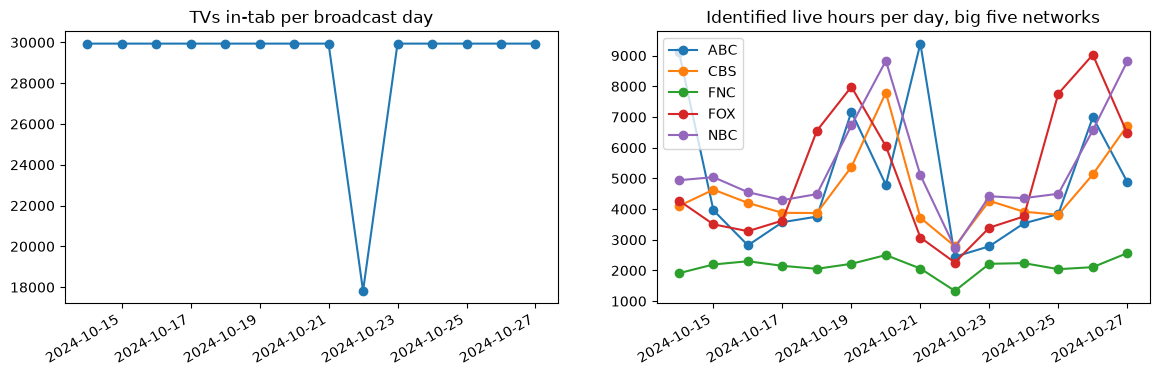

In [37]:
daily = pd.DataFrame({"tvs_in_tab": in_tab})
daily["hours_per_tv"] = edited.groupby("bday")["hours"].sum() / daily["tvs_in_tab"]
big_hours = live[live["network_code"].isin(BIG)].pivot_table(index="bday", columns="network_code", values="hours", aggfunc="sum")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(pd.to_datetime(daily.index), daily["tvs_in_tab"], marker="o")
ax[0].set_title("TVs in-tab per broadcast day")
for net in big_hours.columns:
    ax[1].plot(pd.to_datetime(big_hours.index), big_hours[net], marker="o", label=net)
ax[1].set_title("Identified live hours per day, big five networks")
ax[1].legend()
fig.autofmt_xdate()
plt.show()

## Task 4.2 — Spike and broken day

In [38]:
big_live = live[live["network_code"].isin(BIG)]
spike_day, spike_net = big_live.groupby(["bday", "network_code"])["hours"].sum().idxmax()
print("Biggest spike (date, network):", f"{spike_day}, {spike_net}")

on_air = programs[(programs["network_code"] == spike_net) & (broadcast_day(programs["start_ts"]) == spike_day)]
display(on_air.sort_values("duration_min", ascending=False).head(3)[["start_ts", "program_name", "episode_name", "duration_min"]])

display(daily.round(2))
broken_day = (daily["tvs_in_tab"] - daily["tvs_in_tab"].median()).abs().idxmax()
print("Broken day (date):", broken_day)

Biggest spike (date, network): 2024-10-21, ABC


,start_ts,program_name,episode_name,duration_min
285,2024-10-22 01:05:00,Local / Syndicated Programming,NaN,355
278,2024-10-21 15:00:00,Local / Syndicated Programming,NaN,210
282,2024-10-21 20:15:00,NFL Football,NFL Football: BAL @ TB,190


,tvs_in_tab,hours_per_tv
bday,,
2024-10-14,29940,4.52
2024-10-15,29940,4.46
2024-10-16,29940,4.45
2024-10-17,29940,4.41
2024-10-18,29940,4.39
2024-10-19,29940,5.31
2024-10-20,29940,5.32
2024-10-21,29940,4.56
2024-10-22,17818,4.45


Broken day (date): 2024-10-22


**Answer:** The spike is ABC on 2024-10-21: *NFL Football* aired that night. The broken day is 2024-10-22: in-tab TVs fell by 40.5% (from 29,940 to 17,818) while viewing per TV stayed normal (4.45 hours), so the data changed, not the audience. Unnoticed, it would show a false dip in daily totals, and ratings for that day would be off if the missing TVs are not a random set. I would flag the day, leave it out of daily trends, and drop it from ratings unless the vendor can resend it.

## Task 5.1 — Sampling error vs bias

In [39]:
n_panel = hh.groupby("bday")["respondent_id"].nunique()
three = ref[ref["network_code"].isin(["NBC", "FNC", "HGTV"])].copy()
p = three["hh_rating"] / 100
three["SE footprint"] = np.sqrt(p * (1 - p) / three["bday"].map(in_tab)) * 100
three["SE panel"] = np.sqrt(p * (1 - p) / three["bday"].map(n_panel)) * 100
three["panel SE / footprint SE"] = three["SE panel"] / three["SE footprint"]
three["TVs' rating - reference"] = three["tv_rating"] - three["hh_rating"]
three[["program_name", "network_code", "SE footprint", "SE panel", "tv_rating", "hh_rating", "panel SE / footprint SE", "TVs' rating - reference"]].round(2)

,program_name,network_code,SE footprint,SE panel,tv_rating,hh_rating,panel SE / footprint SE,TVs' rating - reference
1,NFL Football,NBC,0.27,0.75,21.25,33.14,2.77,-11.89
3,Hannity,FNC,0.09,0.24,0.82,2.30,2.78,-1.48
4,Unsellable Houses,HGTV,0.11,0.30,2.10,3.69,2.78,-1.59


**Answer:** The footprint's SE is about 2.8 times smaller than the panel's, only 0.09 to 0.27 rating points. The gap between the TVs' rating and the reference is 1.48 to 11.89 points, many times bigger. That gap is bias: it comes from whose homes are in the footprint and from seeing one TV per home, and more TVs from the same footprint do not shrink it.

## Task 5.2 — Answer to the planner

**Answer:** The currency rating for Sunday Night Football is 33.1; this feed alone reads 21.2, 36.0% too low, so I would not show the feed's number to the client. The feed counts TV sets, not people, so it cannot give a persons or A18-49 rating. It sees one TV per home and misses the other sets, apps that block ACR, and homes that opted out or did not match (only 65.2% of TVs matched one household). Its homes are not representative either: they skew toward higher-income ($50k+ and especially $100k+) and Western/Southern households while under-representing lower-income (under $50k) and older homes. Before using it for planning I would need it weighted to the US universe, checked against the currency on many more telecasts, and linked to persons through the panel.

## Bonus

In [40]:
snf = ref[ref["network_code"] == "NBC"].iloc[0]

v = viewings[viewings["network_code"] == "NBC"]
overlap = (v["end_ts"].clip(upper=snf.end_ts) - v["start_ts"].clip(lower=snf.start_ts)).dt.total_seconds().clip(lower=0)
minutes = (overlap / 60).groupby(v["respondent_id"]).sum()
watched = minutes[minutes >= 1].index

day = dw[dw["bday"] == snf.bday].copy()
day["age"] = day["respondent_id"].map(age)
day["watched"] = day["respondent_id"].isin(watched)
is_hh = day["resp_type"] == "H"
is_a2554 = day["resp_type"].isin(["R", "L"]) & day["age"].between(25, 54)

vpvh = day.loc[is_a2554 & day["watched"], "weight"].sum() / day.loc[is_hh & day["watched"], "weight"].sum()
a2554_rating = snf.tv_rating * vpvh * day.loc[is_hh, "weight"].sum() / day.loc[is_a2554, "weight"].sum()
print("VPVH A25-54:", round(vpvh, 2))
print("A25-54 rating (persons):", round(a2554_rating, 1))

VPVH A25-54: 0.51
A25-54 rating (persons): 11.1


**Answer:** This is personification. It assumes the footprint's viewing homes have the same number of A25-54 viewers per home as the panel's viewing homes. If smart-TV homes are younger or bigger than average, the estimate is off, and it also inherits all the bias of the TVs' household rating.